In [783]:
# Week 6 Integrative Capstone Project
# Student Performance Prediction and Analysis

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    accuracy_score,
    classification_report,
    confusion_matrix
)

print("All libraries imported successfully!")

All libraries imported successfully!


In [784]:
# Load the student performance dataset

file_path = "../data/student-mat.csv"

df = pd.read_csv(file_path, sep=";")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

Dataset loaded successfully!
Dataset shape: (395, 33)


In [785]:
# Display first 5 rows

df.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [786]:
# Data Cleaning

# 1. Check missing values
print("Total missing values:", df.isnull().sum().sum())

# 2. Check duplicate rows
print("Total duplicate rows:", df.duplicated().sum())

# 3. Remove duplicate rows if any
df = df.drop_duplicates()

print("\nAfter cleaning:")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Total missing values: 0
Total duplicate rows: 0

After cleaning:
Rows: 395
Columns: 33


In [787]:
# Check unique values in important categorical columns

categorical_columns = [
    "school", "sex", "address", "famsize",
    "Pstatus", "Mjob", "Fjob", "reason", "guardian"
]

for column in categorical_columns:
    print(f"\n{column}:")
    print(df[column].unique())


school:
<StringArray>
['GP', 'MS']
Length: 2, dtype: str

sex:
<StringArray>
['F', 'M']
Length: 2, dtype: str

address:
<StringArray>
['U', 'R']
Length: 2, dtype: str

famsize:
<StringArray>
['GT3', 'LE3']
Length: 2, dtype: str

Pstatus:
<StringArray>
['A', 'T']
Length: 2, dtype: str

Mjob:
<StringArray>
['at_home', 'health', 'other', 'services', 'teacher']
Length: 5, dtype: str

Fjob:
<StringArray>
['teacher', 'other', 'services', 'health', 'at_home']
Length: 5, dtype: str

reason:
<StringArray>
['course', 'other', 'home', 'reputation']
Length: 4, dtype: str

guardian:
<StringArray>
['mother', 'father', 'other']
Length: 3, dtype: str


In [788]:
# Check grade ranges

print("G1 range:", df["G1"].min(), "to", df["G1"].max())
print("G2 range:", df["G2"].min(), "to", df["G2"].max())
print("G3 range:", df["G3"].min(), "to", df["G3"].max())

G1 range: 3 to 19
G2 range: 0 to 19
G3 range: 0 to 20


In [789]:
# Save cleaned dataset

cleaned_file = "../data/student_performance_cleaned.csv"

df.to_csv(cleaned_file, index=False, sep=";")

print("Cleaned dataset saved successfully!")
print(cleaned_file)

Cleaned dataset saved successfully!
../data/student_performance_cleaned.csv


In [790]:
# Create output directory for charts

import os

charts_path = "../outputs/charts"
os.makedirs(charts_path, exist_ok=True)

print("Charts folder is ready!")

Charts folder is ready!


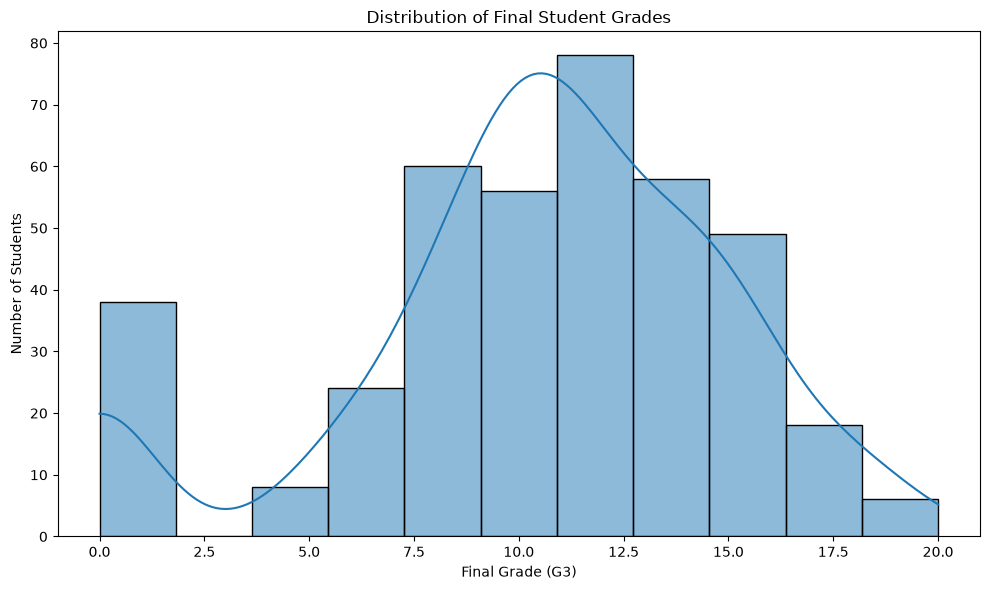

In [791]:
# Distribution of Final Grade (G3)

plt.figure(figsize=(10, 6))

sns.histplot(df["G3"], bins=11, kde=True)

plt.title("Distribution of Final Student Grades")
plt.xlabel("Final Grade (G3)")
plt.ylabel("Number of Students")
plt.tight_layout()

plt.savefig("../outputs/charts/final_grade_distribution.png", dpi=300)
plt.show()

sex
F     9.966346
M    10.914439
Name: G3, dtype: float64


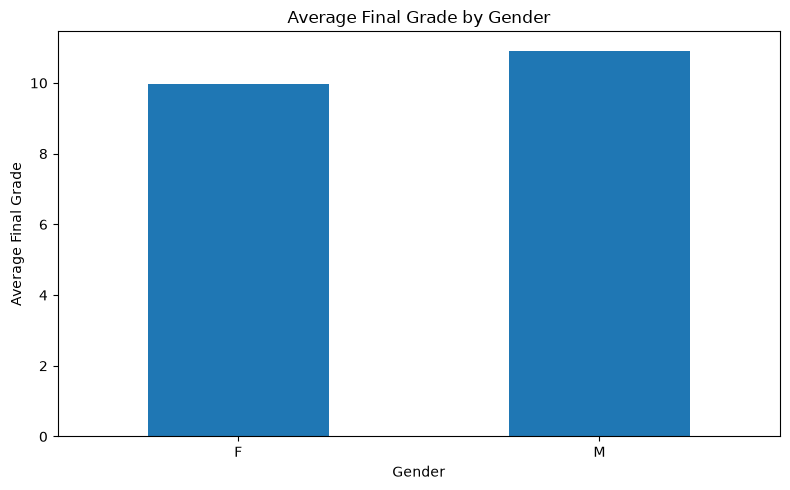

In [792]:
# Gender-wise average final grade

gender_performance = df.groupby("sex")["G3"].mean()

print(gender_performance)

plt.figure(figsize=(8, 5))

gender_performance.plot(kind="bar")

plt.title("Average Final Grade by Gender")
plt.xlabel("Gender")
plt.ylabel("Average Final Grade")
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig("../outputs/charts/gender_performance.png", dpi=300)
plt.show()

studytime
1    10.047619
2    10.171717
3    11.400000
4    11.259259
Name: G3, dtype: float64


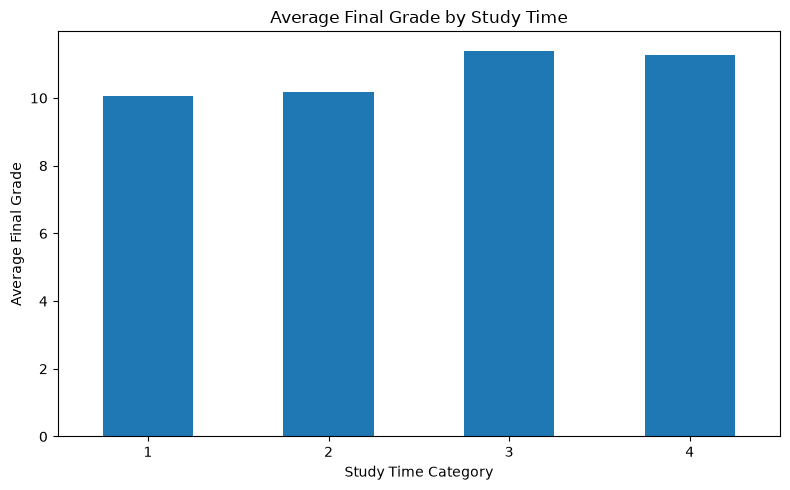

In [793]:
# Study time vs final grade

study_performance = df.groupby("studytime")["G3"].mean()

print(study_performance)

plt.figure(figsize=(8, 5))

study_performance.plot(kind="bar")

plt.title("Average Final Grade by Study Time")
plt.xlabel("Study Time Category")
plt.ylabel("Average Final Grade")
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig("../outputs/charts/study_time_vs_grade.png", dpi=300)
plt.show()

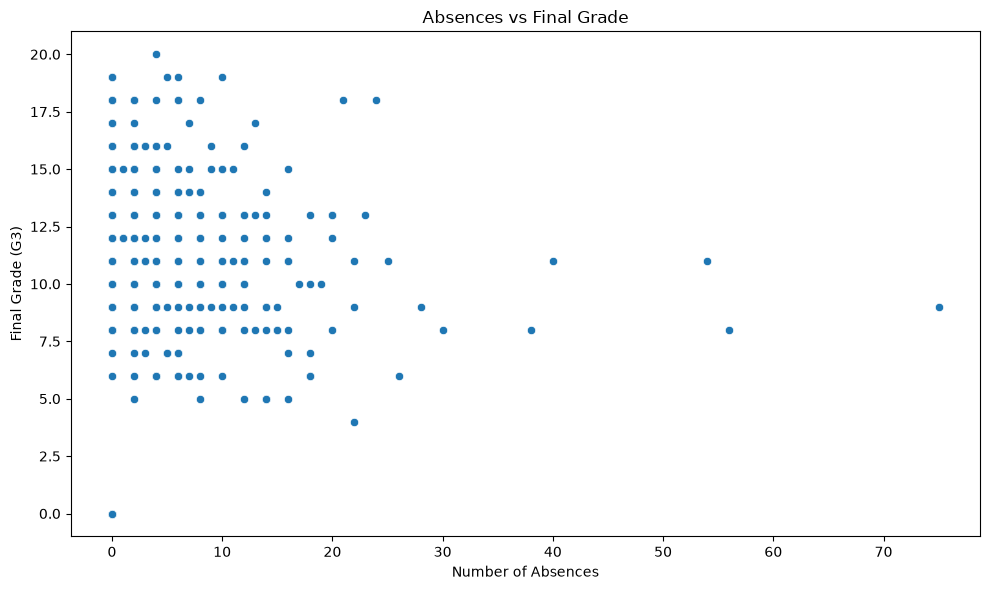

In [794]:
# Absences vs Final Grade

plt.figure(figsize=(10, 6))

sns.scatterplot(data=df, x="absences", y="G3")

plt.title("Absences vs Final Grade")
plt.xlabel("Number of Absences")
plt.ylabel("Final Grade (G3)")
plt.tight_layout()

plt.savefig("../outputs/charts/absences_vs_grade.png", dpi=300)
plt.show()

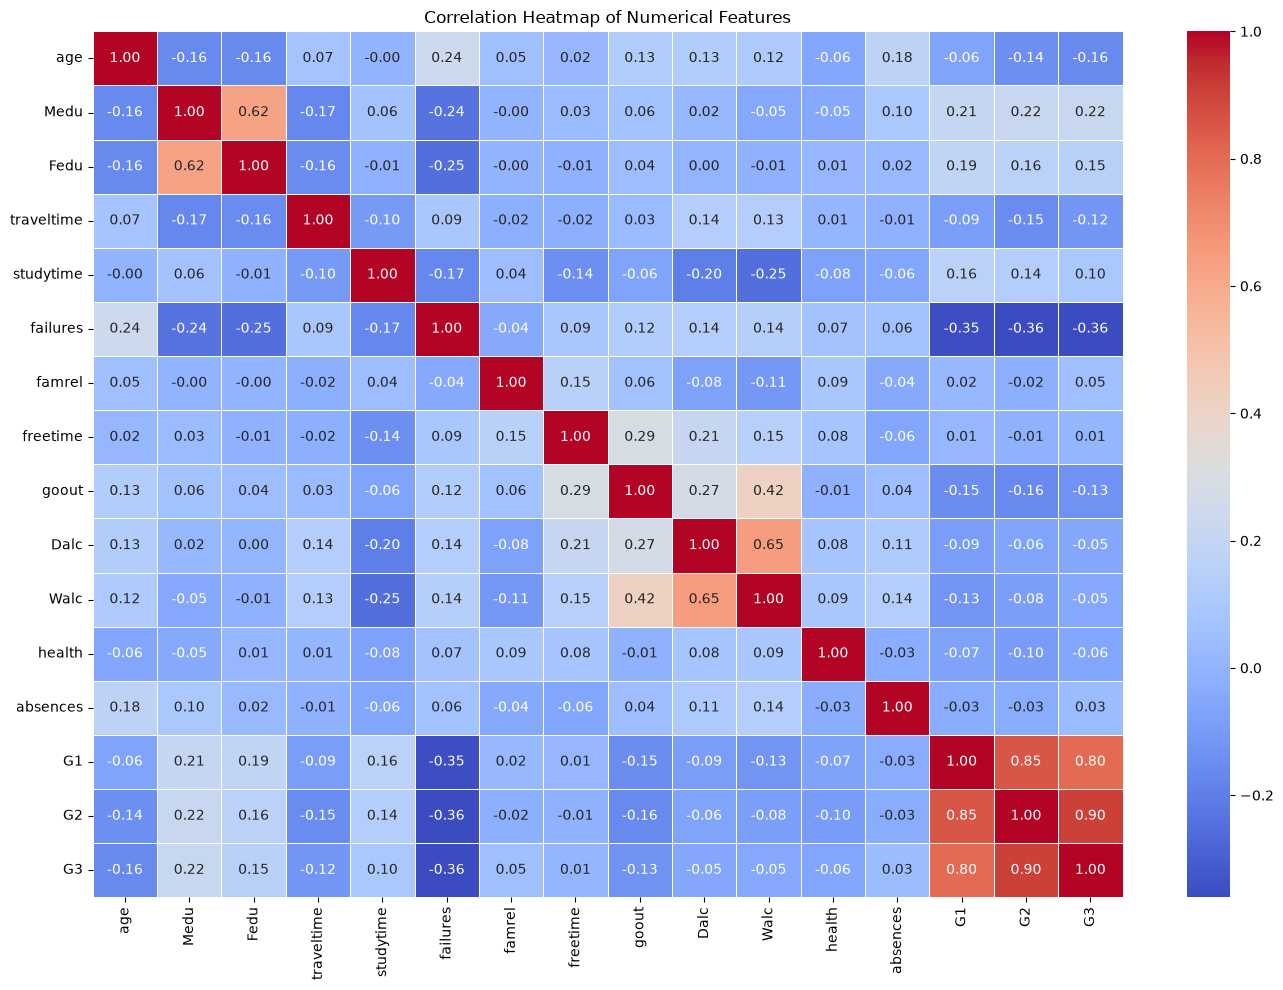

In [795]:
# Correlation analysis of numerical variables

numeric_df = df.select_dtypes(include=np.number)

plt.figure(figsize=(14, 10))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Numerical Features")
plt.tight_layout()

plt.savefig("../outputs/charts/correlation_heatmap.png", dpi=300)
plt.show()

school
GP    10.489971
MS     9.847826
Name: G3, dtype: float64


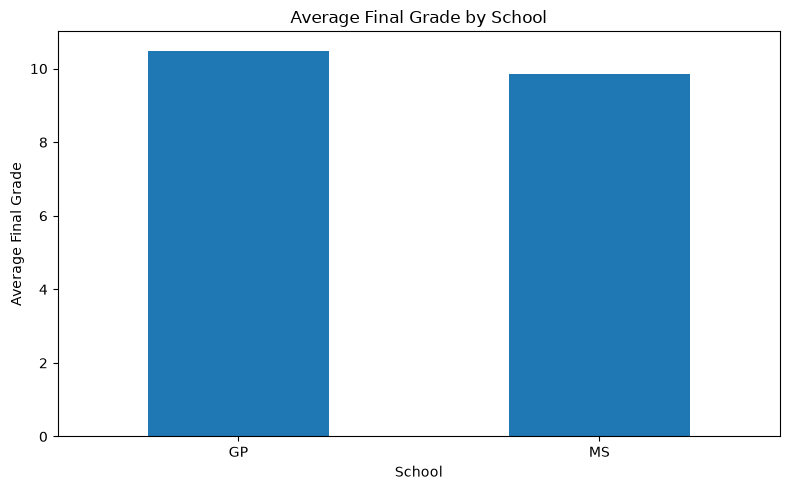

In [796]:
# School-wise average final grade

school_performance = df.groupby("school")["G3"].mean()

print(school_performance)

plt.figure(figsize=(8, 5))

school_performance.plot(kind="bar")

plt.title("Average Final Grade by School")
plt.xlabel("School")
plt.ylabel("Average Final Grade")
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig("../outputs/charts/school_performance.png", dpi=300)
plt.show()

In [797]:
# Unsupervised Learning - K-Means Clustering

from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

# Select numerical features for clustering
cluster_features = df.select_dtypes(include=np.number).drop(
    columns=["G3"],
    errors="ignore"
)

print("Clustering features:")
print(cluster_features.columns.tolist())
print("\nShape:", cluster_features.shape)

Clustering features:
['age', 'Medu', 'Fedu', 'traveltime', 'studytime', 'failures', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2']

Shape: (395, 15)


In [798]:
# Standardize features before clustering

cluster_scaler = StandardScaler()

cluster_scaled = cluster_scaler.fit_transform(cluster_features)

print("Clustering data standardized successfully!")

Clustering data standardized successfully!


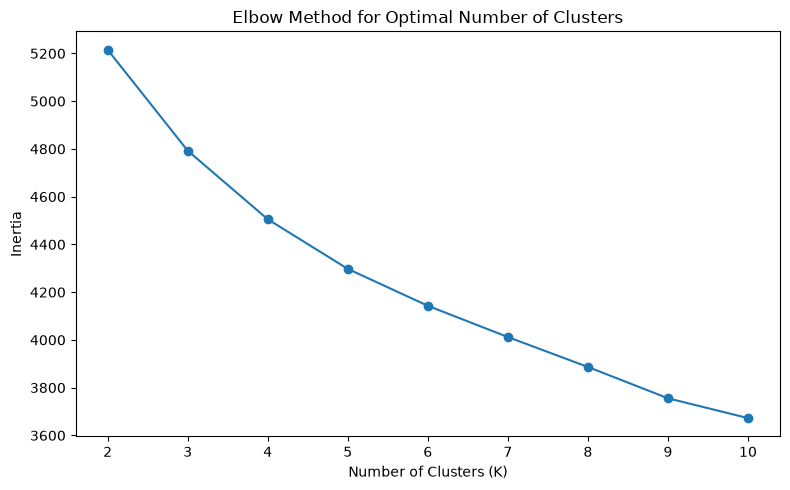

In [799]:
# Elbow Method for selecting number of clusters

inertia_values = []

for k in range(2, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    
    kmeans.fit(cluster_scaled)
    inertia_values.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))

plt.plot(
    range(2, 11),
    inertia_values,
    marker="o"
)

plt.title("Elbow Method for Optimal Number of Clusters")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.xticks(range(2, 11))
plt.tight_layout()

plt.savefig(
    "../outputs/charts/elbow_method.png",
    dpi=300
)

plt.show()

In [800]:
# Apply K-Means clustering with 3 clusters

kmeans_model = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

clusters = kmeans_model.fit_predict(cluster_scaled)

df["Cluster"] = clusters

print("K-Means clustering completed!")
print("\nStudents in each cluster:")
print(df["Cluster"].value_counts().sort_index())

K-Means clustering completed!

Students in each cluster:
Cluster
0    166
1    141
2     88
Name: count, dtype: int64


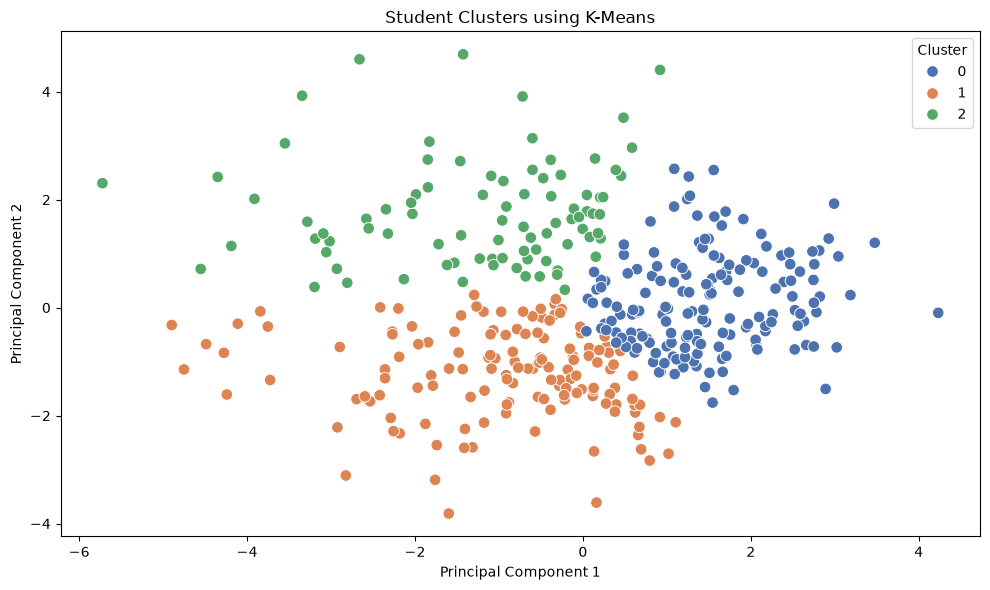

In [801]:
# Visualize student clusters

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="Cluster",
    palette="deep",
    s=70
)

plt.title("Student Clusters using K-Means")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Cluster")

plt.tight_layout()

plt.savefig(
    "../outputs/charts/student_clusters.png",
    dpi=300
)

plt.show()

In [802]:
# Analyze average characteristics of each cluster

cluster_summary = df.groupby("Cluster")[
    ["G1", "G2", "G3", "studytime", "absences"]
].mean()

cluster_summary

,G1,G2,G3,studytime,absences
Cluster,,,,,
0,13.222892,13.253012,13.271084,2.228916,3.981928
1,8.645390,8.113475,7.382979,1.992908,5.503546
2,10.170455,10.090909,9.886364,1.738636,9.295455


In [803]:
# Save clustering results

cluster_summary.to_csv(
    "../outputs/model_results/clustering_summary.csv"
)

df.to_csv(
    "../data/student_performance_clustered.csv",
    index=False,
    sep=";"
)

print("Clustering results saved successfully!")

Clustering results saved successfully!


In [804]:
# Actual vs Predicted Values

comparison_df = pd.DataFrame({
    "Actual_G3": y_test.values,
    "Linear_Regression": y_pred_linear,
    "Random_Forest": y_pred_rf
})

comparison_df.head(10)

,Actual_G3,Linear_Regression,Random_Forest
0,10,5.864446,8.225
1,12,11.546577,11.815
2,5,2.884395,6.630
3,10,8.745638,9.640
4,9,8.603936,8.820
5,13,11.888890,12.800
6,18,19.027166,18.720
7,6,7.160954,6.875
8,0,7.355908,7.000
9,14,12.346118,13.380


In [ ]:
# Actual vs Predicted Final Grades

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_pred_rf,
    alpha=0.7
)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.title("Actual vs Predicted Final Grades - Random Forest")
plt.xlabel("Actual G3")
plt.ylabel("Predicted G3")

plt.tight_layout()

plt.savefig(
    "../outputs/charts/actual_vs_predicted.png",
    dpi=300
)

plt.show()

In [805]:
# Reduce clustering data to 2 dimensions using PCA

pca = PCA(n_components=2)

cluster_pca = pca.fit_transform(cluster_scaled)

pca_df = pd.DataFrame(
    cluster_pca,
    columns=["PC1", "PC2"]
)

pca_df["Cluster"] = df["Cluster"].values

print("Explained variance ratio:")
print(pca.explained_variance_ratio_)

Explained variance ratio:
[0.18900895 0.13312387]


In [806]:
# Feature Engineering
# G3 will be our target variable

# Remove target variable from input features
X = df.drop("G3", axis=1)

# Target variable
y = df["G3"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)
print("\nTarget variable: G3")

Features shape: (395, 33)
Target shape: (395,)

Target variable: G3


In [807]:
# Convert categorical variables into numerical variables

X_encoded = pd.get_dummies(X, drop_first=True)

print("Original feature count:", X.shape[1])
print("Encoded feature count:", X_encoded.shape[1])

print("\nEncoded data shape:", X_encoded.shape)

Original feature count: 33
Encoded feature count: 42

Encoded data shape: (395, 42)


In [808]:
# Split data into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X_encoded,
    y,
    test_size=0.20,
    random_state=42
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 316
Testing samples: 79


In [809]:
# Feature Scaling

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed successfully!")

Feature scaling completed successfully!


In [810]:
# Linear Regression Model

from sklearn.linear_model import LinearRegression

linear_model = LinearRegression()

linear_model.fit(X_train_scaled, y_train)

y_pred_linear = linear_model.predict(X_test_scaled)

print("Linear Regression model trained successfully!")

Linear Regression model trained successfully!


In [811]:
# Evaluate Linear Regression

mae_linear = mean_absolute_error(y_test, y_pred_linear)
rmse_linear = np.sqrt(mean_squared_error(y_test, y_pred_linear))
r2_linear = r2_score(y_test, y_pred_linear)

print("Linear Regression Results")
print("=" * 40)
print("MAE :", round(mae_linear, 3))
print("RMSE:", round(rmse_linear, 3))
print("R²  :", round(r2_linear, 3))

Linear Regression Results
MAE : 1.651
RMSE: 2.391
R²  : 0.721


In [812]:
# Random Forest Regression Model

from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=200,
    random_state=42
)

rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [813]:
# Evaluate Random Forest

mae_rf = mean_absolute_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))
r2_rf = r2_score(y_test, y_pred_rf)

print("Random Forest Results")
print("=" * 40)
print("MAE :", round(mae_rf, 3))
print("RMSE:", round(rmse_rf, 3))
print("R²  :", round(r2_rf, 3))

Random Forest Results
MAE : 1.174
RMSE: 1.964
R²  : 0.812


In [814]:
# Compare model performance

model_results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Random Forest"
    ],
    "MAE": [
        mae_linear,
        mae_rf
    ],
    "RMSE": [
        rmse_linear,
        rmse_rf
    ],
    "R2 Score": [
        r2_linear,
        r2_rf
    ]
})

model_results

,Model,MAE,RMSE,R2 Score
0,Linear Regression,1.650544,2.390575,0.721296
1,Random Forest,1.173797,1.964111,0.811864


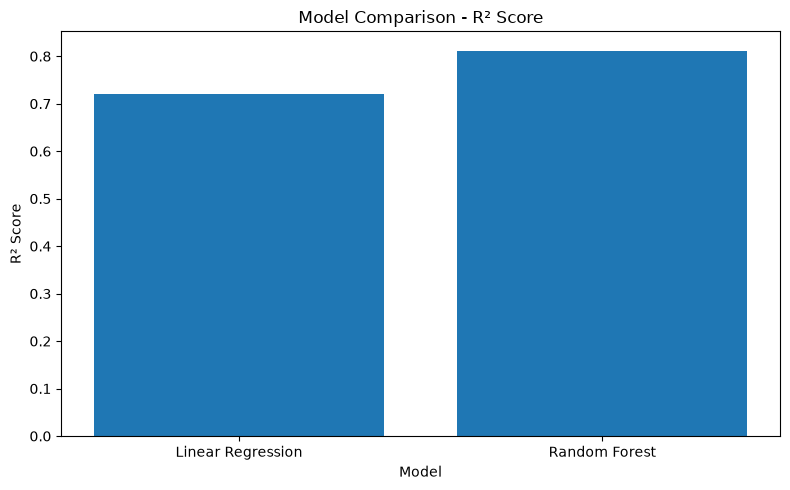

In [815]:
# Visual comparison of R² scores

plt.figure(figsize=(8, 5))

plt.bar(
    model_results["Model"],
    model_results["R2 Score"]
)

plt.title("Model Comparison - R² Score")
plt.xlabel("Model")
plt.ylabel("R² Score")
plt.tight_layout()

plt.savefig(
    "../outputs/charts/model_comparison.png",
    dpi=300
)

plt.show()

In [816]:
# Save model evaluation results

model_results.to_csv(
    "../outputs/model_results/supervised_model_results.csv",
    index=False
)

print("Model results saved successfully!")

Model results saved successfully!


In [817]:
# Check dataset structure and data types

print("Dataset Information:")
print("=" * 50)

df.info()

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 34 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   school      395 non-null    str  
 1   sex         395 non-null    str  
 2   age         395 non-null    int64
 3   address     395 non-null    str  
 4   famsize     395 non-null    str  
 5   Pstatus     395 non-null    str  
 6   Medu        395 non-null    int64
 7   Fedu        395 non-null    int64
 8   Mjob        395 non-null    str  
 9   Fjob        395 non-null    str  
 10  reason      395 non-null    str  
 11  guardian    395 non-null    str  
 12  traveltime  395 non-null    int64
 13  studytime   395 non-null    int64
 14  failures    395 non-null    int64
 15  schoolsup   395 non-null    str  
 16  famsup      395 non-null    str  
 17  paid        395 non-null    str  
 18  activities  395 non-null    str  
 19  nursery     395 non-null    str  
 20  higher      395 non-nu

In [818]:
# Check missing values in each column

missing_values = df.isnull().sum()

print("Missing Values:")
print(missing_values)

print("\nTotal missing values:", missing_values.sum())

Missing Values:
school        0
sex           0
age           0
address       0
famsize       0
Pstatus       0
Medu          0
Fedu          0
Mjob          0
Fjob          0
reason        0
guardian      0
traveltime    0
studytime     0
failures      0
schoolsup     0
famsup        0
paid          0
activities    0
nursery       0
higher        0
internet      0
romantic      0
famrel        0
freetime      0
goout         0
Dalc          0
Walc          0
health        0
absences      0
G1            0
G2            0
G3            0
Cluster       0
dtype: int64

Total missing values: 0


In [819]:
# Check duplicate rows

duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 0


In [820]:
# Statistical summary of numerical columns

df.describe()

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3,Cluster
count,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000
mean,16.696203,2.749367,2.521519,1.448101,2.035443,0.334177,3.944304,3.235443,3.108861,1.481013,2.291139,3.554430,5.708861,10.908861,10.713924,10.415190,0.802532
std,1.276043,1.094735,1.088201,0.697505,0.839240,0.743651,0.896659,0.998862,1.113278,0.890741,1.287897,1.390303,8.003096,3.319195,3.761505,4.581443,0.778188
min,15.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,3.000000,0.000000,0.000000,0.000000
25%,16.000000,2.000000,2.000000,1.000000,1.000000,0.000000,4.000000,3.000000,2.000000,1.000000,1.000000,3.000000,0.000000,8.000000,9.000000,8.000000,0.000000
50%,17.000000,3.000000,2.000000,1.000000,2.000000,0.000000,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,4.000000,11.000000,11.000000,11.000000,1.000000
75%,18.000000,4.000000,3.000000,2.000000,2.000000,0.000000,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,8.000000,13.000000,13.000000,14.000000,1.000000
max,22.000000,4.000000,4.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,75.000000,19.000000,19.000000,20.000000,2.000000


In [821]:
# Display all column names

print("Number of columns:", len(df.columns))
print("\nColumn names:")
for column in df.columns:
    print(column)

Number of columns: 34

Column names:
school
sex
age
address
famsize
Pstatus
Medu
Fedu
Mjob
Fjob
reason
guardian
traveltime
studytime
failures
schoolsup
famsup
paid
activities
nursery
higher
internet
romantic
famrel
freetime
goout
Dalc
Walc
health
absences
G1
G2
G3
Cluster
